# 모듈 2 · NLP 미니프로젝트 — BERT 기반 한국어 의미 검색 시스템 개발 및 성능 비교

**기간:** 2일·총 16교시 · **체크포인트:** Day 1 `CP-01~06`, Day 2 `CP-07~10`  
**검색 모델:** TF-IDF · `klue/bert-base` · 한국어 Sentence-BERT  
**최종 결과물:** `search_docs()` + 검색 성능 보고서 + 기술적 의사결정 기록(ADR)

> 이 프로젝트는 GPT로 답변을 생성하거나 BERT를 재학습하는 프로젝트가 아닙니다. **문서의 표현 → 유사도 계산 → Top-k 검색 → 정답 평가 → 오류 분석 → 최종 검색 방식 선정**을 직접 개발합니다.
>
> **학생용 안내:** `[학생 구현]` 셀의 `TODO`를 작성하고 `raise NotImplementedError(...)`를 지운 뒤 `[공통 검증]` 셀을 실행하세요. `[기록]`으로 표시된 Markdown 셀은 실제 결과를 보고 직접 작성합니다. `생각해 볼 질문`은 별도 제출이 아닙니다.


## 00. 환경 설치와 세션 초기화 복구

GPU 세션이 초기화되더라도 첫 코드 셀부터 다시 실행할 수 있도록 구성했습니다. 패키지·모델 가중치·데이터가 없는 경우 자동으로 준비하며, 이미 저장된 파일은 재사용합니다.


**환경 설치(공통).** 필요한 Python 패키지를 한 번에 점검하고 누락되거나 호환 범위를 벗어난 패키지만 설치합니다. GPU 이미지에 이미 설치된 CUDA용 PyTorch는 가능한 한 유지하며, 설치 후 CUDA 상태를 확인합니다.


In [68]:
# [공통] 00-1 — 필요한 패키지 자동 설치
import sys, subprocess, importlib.metadata as im
from importlib.util import find_spec

# Python 패키지가 GPU 세션 초기화로 사라진 경우에도 첫 셀부터 복구합니다.
# RunPod GPU 이미지의 PyTorch/CUDA 조합은 가능하면 변경하지 않습니다.
requirements = [
    ('torch', 'torch>=2.2', '2.2'),
    ('numpy', 'numpy>=1.24', '1.24'),
    ('pandas', 'pandas>=2.0', '2.0'),
    ('matplotlib', 'matplotlib>=3.7', '3.7'),
    ('sklearn', 'scikit-learn>=1.3', '1.3'),
    ('transformers', 'transformers>=4.46,<5', '4.46'),
    ('datasets', 'datasets>=3.0,<5', '3.0'),
    ('sentence_transformers', 'sentence-transformers>=3.0,<6', '3.0'),
    ('safetensors', 'safetensors>=0.4', '0.4'),
]

# 설치 확인에는 표준 라이브러리만 사용합니다.
to_install = []
for module, spec, min_version in requirements:
    if find_spec(module) is None:
        to_install.append(spec)
    else:
        try:
            package = {'sklearn': 'scikit-learn', 'sentence_transformers': 'sentence-transformers'}.get(module, module)
            version = im.version(package)
            major_minor = tuple(int(x) for x in version.split('.')[:2])
            required = tuple(int(x) for x in min_version.split('.'))
            if major_minor < required or (module in ('transformers','datasets') and int(version.split('.')[0]) >= 5):
                to_install.append(spec)
        except (im.PackageNotFoundError, ValueError):
            to_install.append(spec)

if to_install:
    print('설치/갱신:', ', '.join(to_install))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *to_install])
else:
    print('필수 패키지가 이미 준비되어 있습니다.')

# 이미 import한 구버전 라이브러리가 변경된 경우에는 커널 재시작 후 다시 실행하세요.
print('Python:', sys.version.split()[0])


필수 패키지가 이미 준비되어 있습니다.
Python: 3.12.3


**작업 폴더와 장치 확인(공통).** `/workspace`가 있으면 프로젝트 파일을 그 아래에, 그 외 환경은 현재 작업 폴더 아래에 보관합니다. 모든 파일·폴더는 처음 실행할 때 자동으로 생성되며 추론 결과는 재실행 시 캐시를 재사용합니다.


In [100]:
# [공통] 00-2 — 프로젝트 경로·GPU·캐시 설정
import os, json, re, hashlib, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = (Path('/workspace') if Path('/workspace').is_dir() else Path.cwd()) / 'nlp_bert_mini'
DATA_RAW = ROOT / 'data' / 'raw'
DATA_PROCESSED = ROOT / 'data' / 'processed'
WEIGHTS = ROOT / 'weights'
CACHE = ROOT / 'outputs' / 'cache'
TABLES = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures'
REPORTS = ROOT / 'outputs' / 'reports'
DOCS = ROOT / 'docs'
for folder in [DATA_RAW, DATA_PROCESSED, WEIGHTS, CACHE, TABLES, FIGURES, REPORTS, DOCS]:
    folder.mkdir(parents=True, exist_ok=True)

os.environ['HF_HOME'] = str(WEIGHTS / 'huggingface')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('실습 루트:', ROOT)
print('PyTorch:', torch.__version__, '| Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('GPU가 없어 CPU로 실행합니다. BERT 임베딩 계산은 더 오래 걸릴 수 있습니다.')

# [공통] CP-08의 Sentence-BERT 가중치(pytorch_model.bin)는 PyTorch 버전이 낮으면 읽지 못할 수 있어 미리 확인합니다.
try:
    _torch_major_minor = tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2])
except ValueError:
    _torch_major_minor = None
if _torch_major_minor is not None and _torch_major_minor < (2, 6):
    print('[주의] PyTorch가 2.6 미만입니다. Day 2의 CP-08에서 Sentence-BERT 로딩이 실패할 수 있으니 강사에게 알려 주세요.')


실습 루트: /workspace/nlp_bert_mini
PyTorch: 2.8.0+cu128 | Device: cuda
GPU: NVIDIA GeForce RTX 4090


### 세션 초기화 시 재실행 방법

1. GitHub에는 **작성한 Notebook과 최종 문서**를 저장하세요. 대용량 모델·원본 데이터는 업로드하지 않습니다.
2. 다음 날 Notebook을 내려받아 **00번 환경 셀부터 순서대로 실행**하면 폴더와 다운로드 데이터가 자동으로 준비됩니다.
3. `/workspace`가 영구 볼륨에 연결되어 있으면 캐시를 재사용합니다. 컨테이너가 삭제되는 환경에서는 다운로드와 임베딩 계산이 다시 진행될 수 있습니다.
4. CP-01~09는 Validation 질문만 사용합니다. **Test 질문의 정답은 CP-10에서 처음 열어 최종 평가**합니다.

**저장 위치:** `data/processed/` (문서·질문), `weights/` (모델 캐시), `outputs/cache/` (문서 벡터), `outputs/tables/` (성능표), `outputs/figures/` (그래프), `outputs/reports/` (결정·최종 평가).


# Day 1 — 한국어 문서 검색기 구현

**목표:** 데이터를 탐색하고 TF-IDF 검색기와 BERT 검색기를 직접 구현합니다. Day 1의 함수들은 Day 2 평가·모델 비교에서 그대로 사용합니다.

---
## CP-01. 문서·질문·정답 구조 분석 및 검색 성능 가설 수립

이번 프로젝트는 KLUE-MRC의 질문–문단 데이터를 **검색 문제**로 다시 구성합니다. 원래 KLUE-MRC는 독해/정답 구간 추출 데이터이며, 본 프로젝트는 정답 문단 하나를 연결하는 별도 검색 평가 데이터이므로 공식 KLUE-MRC 점수와 다릅니다.


**KLUE-MRC 자동 데이터 준비(공통).** 공개 데이터에서 답이 존재하는 질문과 중복되지 않는 문단을 선별해 문단 200개, Validation 질문 60개, 보류 Test 질문 20개를 만듭니다. 질문과 문단은 문서 ID로 연결되며, Test 정답은 CP-10 이전에는 열지 않습니다.


In [70]:
# [공통] CP-01 — 검색용 Corpus / Validation / 보류 Test 자동 준비
from datasets import load_dataset

CORPUS_FILE = DATA_PROCESSED / 'corpus_200.csv'
VALID_FILE = DATA_PROCESSED / 'questions_validation_60.csv'
TEST_FILE = DATA_PROCESSED / 'questions_test_20.csv'
META_FILE = DATA_PROCESSED / 'dataset_meta.json'

# KLUE-MRC 공식 Hugging Face 데이터셋 (validation split만 사용)
# 기존 데이터가 저장되어 있으면 다시 다운로드·선별하지 않습니다.
if not all(f.is_file() for f in (CORPUS_FILE, VALID_FILE, TEST_FILE, META_FILE)):
    raw = load_dataset('klue/klue', 'mrc', split='validation', cache_dir=str(DATA_RAW))
    eligible = []
    seen_contexts = set()
    seen_questions = set()
    for r in raw:
        if bool(r['is_impossible']):
            continue
        context, question = str(r['context']).strip(), str(r['question']).strip()
        if len(context) < 150 or not question or context in seen_contexts or question in seen_questions:
            continue
        answers = r['answers']
        answer_texts = answers.get('text', []) if isinstance(answers, dict) else []
        answer_starts = answers.get('answer_start', []) if isinstance(answers, dict) else []
        if not answer_texts:
            continue
        answer_text = str(answer_texts[0]).strip()
        if not answer_text or answer_text not in context:
            continue
        # ### 답변이 포함된 500자 이내의 문단으로 줄입니다.
        # ### (토큰 수가 MAX_LENGTH를 넘는 문단은 BERT에 넣을 때 뒷부분이 잘릴 수 있습니다.)
        answer_pos = context.find(answer_text)
        left = max(0, min(answer_pos - 180, max(0, len(context) - 500)))
        snippet = context[left:left + 500].strip()
        if answer_text not in snippet:
            continue
        eligible.append({'title': str(r.get('title', '')), 'text': snippet,
                         'question': question, 'guid': str(r['guid'])})
        seen_contexts.add(context)
        seen_questions.add(question)

    assert len(eligible) >= 200, f'선별 가능한 문단이 200개보다 적습니다: {len(eligible)}'
    rng = np.random.default_rng(SEED)
    selected = [eligible[i] for i in rng.choice(len(eligible), size=200, replace=False)]
    docs = [{'doc_id': f'D{i:03d}', 'title': r['title'], 'text': r['text']}
            for i, r in enumerate(selected)]
    corpus_out = pd.DataFrame(docs)
    candidate_idx = rng.permutation(200)[:80]
    qrows = [{'question': selected[int(idx)]['question'],
              'relevant_doc_id': f'D{int(idx):03d}'} for idx in candidate_idx]
    validation_out = pd.DataFrame([
        {'query_id': f'QV{i+1:03d}', **row} for i, row in enumerate(qrows[:60])])
    test_out = pd.DataFrame([
        {'query_id': f'QT{i+1:03d}', **row} for i, row in enumerate(qrows[60:])])

    corpus_out.to_csv(CORPUS_FILE, index=False, encoding='utf-8-sig')
    validation_out.to_csv(VALID_FILE, index=False, encoding='utf-8-sig')
    test_out.to_csv(TEST_FILE, index=False, encoding='utf-8-sig')
    META_FILE.write_text(json.dumps({
        'source': 'klue/klue · mrc · validation', 'seed': SEED,
        'num_documents': 200, 'num_validation_queries': 60, 'num_test_queries': 20,
        'sampling': 'unique contexts; one labeled relevant snippet per question',
        'notes': '수업용 단일 정답 문단 검색 세트. KLUE-MRC의 공식 검색 벤치마크가 아님.'
    }, ensure_ascii=False, indent=2), encoding='utf-8')
    print('KLUE-MRC 데이터로 검색용 소규모 데이터셋을 새로 생성했습니다.')
else:
    print('저장된 프로젝트 데이터셋을 재사용합니다.')

corpus_df = pd.read_csv(CORPUS_FILE, dtype={'doc_id': str}).fillna('')
valid_df = pd.read_csv(VALID_FILE, dtype={'query_id': str, 'relevant_doc_id': str}).fillna('')
assert len(corpus_df) == 200 and len(valid_df) == 60
assert valid_df['relevant_doc_id'].isin(corpus_df['doc_id']).all()
assert corpus_df['doc_id'].is_unique
print('문서:', len(corpus_df), '| Validation 질문:', len(valid_df), '| 별도 보류 Test: 20문항')
display(corpus_df[['doc_id', 'title', 'text']].head(3))
display(valid_df.head(3))

저장된 프로젝트 데이터셋을 재사용합니다.
문서: 200 | Validation 질문: 60 | 별도 보류 Test: 20문항


,doc_id,title,text
0,D000,관 (쓰개),13세기 초 인도 남부에서 채굴된 코이누르 다이아몬드는 무굴제국 등 여러 왕가의 소...
1,D001,도망자 (1995년 영화),"캄보디아 내전 시기. CIA 소속 첩보원인 아화, 아상, 그리고 뇌룡 3인은 캄보디..."
2,D002,기업들 “공공료 다 올려놓고 …”,정부 출범 초마다 어김없이 반복되는 물가 안정 대책에 업계는 바짝 긴장하고 있다. ...


,query_id,question,relevant_doc_id
0,QV001,종교 개혁 전 영국에서 인기를 끌었던 헌신은?,D015
1,QV002,세 종류의 배터리 용량을 선택할 수 있는 폭스바겐의 전기차 모델은?,D092
2,QV003,70억달러가 국비로 충당된 올림픽은?,D022


In [71]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'hf_transfer'])

import huggingface_hub.constants as c
c.HF_HUB_ENABLE_HF_TRANSFER = False
print('완료')

완료


**데이터 탐색·시각화(학생 구현).** 질문과 문단의 글자 수를 계산하고 길이 분포를 그림으로 정리합니다. 관찰 결과를 바탕으로 TF-IDF와 BERT가 각각 어떤 질문에서 유리할지 예상하고 CP-09에서 다시 확인합니다.


문서 길이 통계


count    200.0
mean     499.7
std        0.5
min      498.0
25%      499.0
50%      500.0
75%      500.0
max      500.0
Name: char_length, dtype: float64

질문 길이 통계


count    60.0
mean     29.2
std       8.4
min      13.0
25%      23.8
50%      28.0
75%      36.0
max      54.0
Name: char_length, dtype: float64

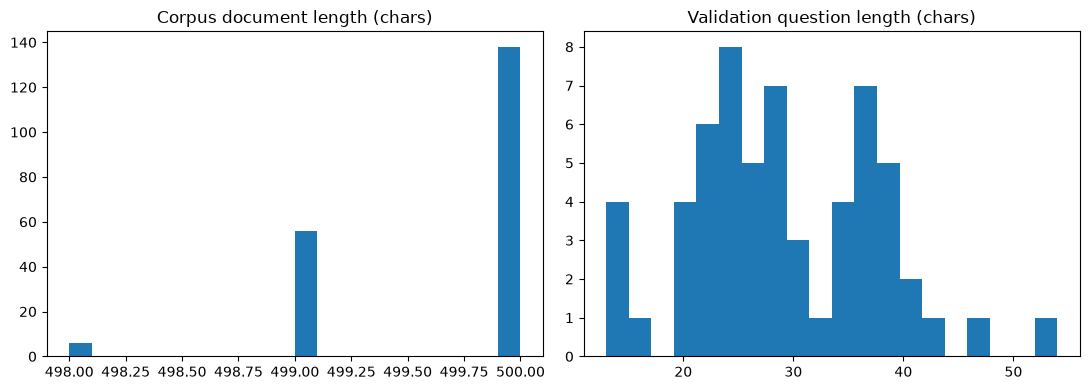

In [72]:
# [학생 구현] CP-01 — 데이터 길이 분석 및 시각화
corpus_stats = corpus_df.copy()
valid_stats = valid_df.copy()

corpus_stats['char_length'] = corpus_stats['text'].str.len()
valid_stats['char_length'] = valid_stats['question'].str.len()

print('문서 길이 통계')
display(corpus_stats['char_length'].describe().round(1))
print('질문 길이 통계')
display(valid_stats['char_length'].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(corpus_stats['char_length'], bins=20)
axes[0].set_title('Corpus document length (chars)')
axes[1].hist(valid_stats['char_length'], bins=20)
axes[1].set_title('Validation question length (chars)')
fig.tight_layout()
fig.savefig(FIGURES / 'cp01_length_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


**질문–정답 문단 겹침 분석(공통).** TF-IDF는 질문과 문단에 같은 글자 묶음이 많이 나올수록 유리합니다. 질문의 글자 2개 묶음(2-gram) 가운데 정답 문단에도 나오는 비율을 질문마다 계산해 `valid_overlap`에 저장합니다. 겹침 비율이 낮은 질문은 문단과 다른 표현으로 물어본 질문입니다. 코드는 제공되며, 학생들은 표를 읽고 아래 기록을 작성합니다. 이 표는 CP-09에서 검색에 실패한 질문과 다시 비교합니다.

In [73]:
# [공통] CP-01 — 질문과 정답 문단의 글자 겹침 비율 (Validation 질문만 사용)

def char_bigrams(text):
    """어절 안에서 만든 글자 2개 묶음의 집합. 예: '검색 성능' → {'검색', '성능'}"""
    return {word[i:i + 2] for word in str(text).split() for i in range(len(word) - 1)}


def overlap_ratio(question, document):
    """질문의 글자 2-gram 중 문단에도 등장하는 비율(0~1)."""
    question_grams = char_bigrams(question)
    if not question_grams:
        return 0.0
    return len(question_grams & char_bigrams(document)) / len(question_grams)


_doc_text = corpus_df.set_index('doc_id')['text']
valid_overlap = valid_df[['query_id', 'question', 'relevant_doc_id']].copy()
valid_overlap['overlap'] = [overlap_ratio(q, _doc_text[d])
                            for q, d in zip(valid_overlap['question'], valid_overlap['relevant_doc_id'])]
print('질문–정답 문단 겹침 비율 통계:')
display(valid_overlap['overlap'].describe().to_frame('겹침 비율').round(3))
print('겹침 비율이 가장 낮은 질문 5개:')
display(valid_overlap.sort_values('overlap').head(5)[['query_id', 'question', 'overlap']].round(3))
valid_overlap.to_csv(TABLES / 'cp01_validation_overlap.csv', index=False, encoding='utf-8-sig')

질문–정답 문단 겹침 비율 통계:


,겹침 비율
count,60.000
mean,0.474
std,0.175
min,0.158
25%,0.333
50%,0.462
75%,0.601
max,0.882


겹침 비율이 가장 낮은 질문 5개:


,query_id,question,overlap
17,QV018,소위 천의 여왕으로 불리는 인물이 대륙에 발표한 방책은 무엇인가?,0.158
45,QV046,싸움에 대비한 체육을 다룬 교육의 명칭은?,0.167
51,QV052,한국전쟁은 남한이 일으켰다고 주장한 사람은?,0.200
50,QV051,누구나 쇼핑몰을 할 수 있게 된 것 같은 변화가 제조업에서도 일어날 수 있는 것은 ...,0.217
8,QV009,영국은 어느나라와의 싸움에서 승리해 코이누르 보석을 습득했나요?,0.227


**[기록] 결과 해석 — CP-01**

- 문서 길이와 질문 길이 분포에서 관찰한 특징: 문서는 모두 498~500자(평균 499.7자)로 거의 같은 길이입니다. 데이터를 만들 때 문단을 최대 500자로 잘랐기 때문입니다. 반면 질문은 13~54자(평균 29.2자, 중앙값 28자)로 문서보다 훨씬 짧고 길이 편차가 큽니다(표준편차 8.4). 질문 한 개가 담은 단서는 적고, 문서 한 개에는 많은 정보가 들어 있습니다. 또한 문서가 모두 같은 길이라 길이 차이가 검색 점수에 미치는 영향은 작을 것으로 보입니다.

- 질문–정답 문단 겹침 비율 분포에서 관찰한 특징: 겹침 비율은 평균 0.474, 중앙값 0.462, 최소 0.158, 최대 0.882로, 질문마다 편차가 매우 큽니다(표준편차 0.175). 평균적으로 질문의 글자 2-gram 중 절반 정도만 정답 문단에 그대로 나타나며, 겹침이 낮은 질문(QV018 0.158, QV046 0.167, QV052 0.200)은 질문이 문단과 다른 표현으로 쓰였습니다.

- 가설 1 — TF-IDF가 잘 찾을 것으로 예상하는 질문과 이유: 질문의 핵심 어구나 고유명사가 정답 문단에 그대로 등장해 겹침 비율이 높은 질문에서 잘 찾을 것입니다. TF-IDF는 문자 2~3-gram이 같은 문서에 점수를 주므로, 겹침이 높을수록 질문과 정답 문단의 벡터가 가까워집니다.

- 가설 2 — BERT 기반 검색에서 유리하거나 불리할 것 같은 질문과 이유: 겹침 비율이 낮아도 의미가 비슷한 질문에서는 BERT 계열이 유리할 것입니다. 문맥 임베딩은 표현이 달라도 의미가 가까우면 벡터가 비슷해질 수 있기 때문입니다. 다만 일반 BERT는 문장 유사도를 따로 학습하지 않았으므로 Sentence-BERT보다 불리할 수 있고, 문서가 256토큰을 넘으면 뒷부분이 잘려 정보를 잃을 수 있습니다.

**[CP-01 완료 기준]** 문서·질문 길이 통계와 그래프를 만들고 겹침 비율 표를 확인한 뒤, 두 검색 방식의 예상 강점·한계를 기록합니다. **Test 질문은 열지 않습니다.**


---
## CP-02. TF-IDF 기반 기준 검색기 구현

TF-IDF는 이미 배운 전통적인 텍스트 표현 방법입니다. 이번에는 한국어 띄어쓰기의 영향을 줄이기 위해 **문자 2~3-gram TF-IDF**를 기준선으로 사용하고, 질문과 문단 간 유사도로 Top-k를 찾습니다.


**TF-IDF 검색기(학생 구현).** 문서 전체의 벡터를 만든 뒤 질문을 같은 TF-IDF 기준으로 변환합니다. 코사인 유사도에 따라 점수를 정렬하고, 앞에서부터 k개의 문서를 반환합니다.


In [74]:
# [학생 구현] CP-02 — TF-IDF + 공통 Top-k 정렬 함수
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 2-1, 2-2. 문서를 TF-IDF 숫자 벡터로 바꾸기
tfidf_vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(2, 3), max_features=30000)
tfidf_docs = tfidf_vectorizer.fit_transform(corpus_df['text'])


def top_k_results(scores, frame, k=5):
    """점수가 높은 문서 k개를 반환합니다. 키: rank, doc_id, score, text"""
    scores = np.asarray(scores, dtype=np.float64).ravel()
    assert len(scores) == len(frame)
    k = min(max(1, int(k)), len(frame))
    # 2-3. 점수 높은 순으로 정렬해서 상위 k개의 위치(인덱스) 고르기
    top_idx = np.argsort(-scores)[:k]
    # 2-4. 순위·문서ID·점수·본문을 딕셔너리로 정리
    results = []
    for rank, idx in enumerate(top_idx, start=1):
        row = frame.iloc[int(idx)]
        results.append({'rank': rank,
                        'doc_id': row['doc_id'],
                        'score': float(scores[idx]),
                        'text': row['text']})
    return results


def search_tfidf(query, k=5):
    # 2-5. 질문을 같은 기준으로 벡터화 (fit이 아니라 transform)
    query_vec = tfidf_vectorizer.transform([str(query)])
    # 2-6. 질문과 모든 문서의 유사도 계산
    scores = cosine_similarity(query_vec, tfidf_docs).ravel()
    # 2-7. 상위 k개 반환
    return top_k_results(scores, corpus_df, k)


# 2-8. 질문 하나로 Top-3 확인
q = valid_df.iloc[0]['question']
print('질문:', q)
print('정답 문서:', valid_df.iloc[0]['relevant_doc_id'])
for hit in search_tfidf(q, 3):
    print(hit['rank'], hit['doc_id'], round(hit['score'], 3), hit['text'][:60])

질문: 종교 개혁 전 영국에서 인기를 끌었던 헌신은?
정답 문서: D015
1 D015 0.142 그것이 표준이다. 다른 장면 세트와 마찬가지로, 그림, 아이보리 미니어처 조각, 재판 드라마, 음악 등 매체
2 D078 0.07 산업 혁명
 산업혁명은 단순한 생산기술의 혁신에 의해서 발생한 생산성의 비약적 증대가 아니라 공장제 수공업(
3 D175 0.066 마이클 베이 감독의 ‘트랜스포머:사라진 시대(사진)’가 중국에서 개봉한 영화 중 최고 흥행기록을 세웠다. 지


**TF-IDF 검색 검증(공통).** 점수가 가장 큰 문서가 첫 번째 결과로 반환되어야 합니다. 검색 함수가 `rank·doc_id·score·text`를 모두 반환해야 BERT 검색과 같은 평가기를 재사용할 수 있습니다.


In [75]:
# [공통 검증] CP-02
_demo_corpus = pd.DataFrame({'doc_id': ['A', 'B', 'C'], 'text': ['가', '나', '다']})
_demo_rank = top_k_results([0.2, 0.9, 0.4], _demo_corpus, 2)
assert [h['doc_id'] for h in _demo_rank] == ['B', 'C']
assert list(_demo_rank[0]) == ['rank', 'doc_id', 'score', 'text']
assert tfidf_docs.shape[0] == len(corpus_df)
_check = search_tfidf(valid_df.iloc[0]['question'], 5)
assert len(_check) == 5 and len(set(h['doc_id'] for h in _check)) == 5
print('CP-02 통과: TF-IDF 검색과 Top-k 정렬 완료')


CP-02 통과: TF-IDF 검색과 Top-k 정렬 완료


**[CP-02 완료 기준]** TF-IDF 문서 행렬을 만들고 `search_tfidf(query, k)`가 유사도 내림차순의 결과를 반환하며 검증 셀을 통과합니다.


---
## CP-03. BERT Encoder 출력과 입력 Shape 분석

기존 KLUE-YNAT 뉴스 분류에서는 BERT 출력으로 분류했습니다. 이번에는 Classification Head가 아닌 **BERT Encoder의 토큰별 문맥 벡터(`last_hidden_state`)**를 문서 표현에 사용합니다.


**BERT 모델 로딩(공통).** `klue/bert-base`를 불러와 추론 모드로 전환합니다. 다운로드된 가중치는 `weights/`에 저장되므로 GPU 세션이 유지되는 동안 반복 다운로드하지 않습니다.


In [101]:
# [공통] CP-03 — BERT Encoder·Tokenizer 준비
from transformers import AutoTokenizer, AutoModel

BASE_MODEL = 'klue/bert-base'
MAX_LENGTH = 256
BATCH_SIZE = 16

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, cache_dir=str(WEIGHTS))
bert_model = AutoModel.from_pretrained(BASE_MODEL, cache_dir=str(WEIGHTS), use_safetensors=True)
bert_model = bert_model.to(DEVICE).eval()
print('BERT Encoder:', BASE_MODEL, '| hidden_size:', bert_model.config.hidden_size)


BERT Encoder: klue/bert-base | hidden_size: 768


**BERT 입력·출력 구조 확인(학생 구현).** 서로 다른 길이의 질문 두 개를 Batch로 묶고 `attention_mask`와 `last_hidden_state`의 Shape를 확인합니다. 토큰마다 벡터가 하나씩 있으므로 아직 문장 하나당 벡터 하나인 상태가 아님을 확인하세요.


In [79]:
# [학생 구현] CP-03 — 토큰 단위 문맥 벡터 확인
sample_questions = valid_df['question'].head(2).astype(str).tolist()

# 3-1. 질문 2개를 BERT가 읽을 수 있는 숫자 텐서로 변환
inputs = tokenizer(sample_questions, padding=True, truncation=True,
                   max_length=MAX_LENGTH, return_tensors='pt')

# 3-2. GPU(또는 CPU)로 옮기기
inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

# 3-3. BERT 실행 (학습이 아니라 계산만 하는 모드)
with torch.inference_mode():
    outputs = bert_model(**inputs)

# 3-4. 결과 저장 (다음 CP-04에서 이 이름을 그대로 씁니다)
last_hidden = outputs.last_hidden_state
mask = inputs['attention_mask']

print('last_hidden Shape:', tuple(last_hidden.shape))
print('mask Shape:', tuple(mask.shape))
print('문장별 유효 토큰 수:', mask.sum(dim=1).tolist())


last_hidden Shape: (2, 19, 768)
mask Shape: (2, 19)
문장별 유효 토큰 수: [15, 19]


**[기록] 결과 해석 — CP-03**

- `last_hidden_state`의 세 차원(Batch·Token·Hidden)이 각각 의미하는 것: 실행 결과 Shape는 (2, 19, 768)이었습니다. 첫 번째 차원 2는 Batch로 한 번에 처리한 문장(질문) 수이고, 두 번째 차원 19는 Token으로 Padding을 포함해 가장 긴 문장에 맞춘 토큰 위치 수입니다. 세 번째 차원 768은 Hidden으로 각 토큰을 표현하는 벡터의 특징 차원입니다. 즉 토큰마다 768차원 문맥 벡터가 하나씩 있어서, 아직 문장 하나당 벡터 하나는 아닙니다.

- `attention_mask`가 0인 위치를 평균에서 제외해야 하는 이유: 문장마다 길이가 달라 짧은 문장은 [PAD] 토큰으로 채워집니다. 실제로 두 질문의 유효 토큰 수는 15개와 19개였고, 짧은 질문에는 Padding 4개가 붙었습니다. Padding은 의미 없는 위치인데 평균에 포함하면 문장 벡터가 Padding 벡터 쪽으로 끌려가 문장의 실제 의미를 왜곡하고, 같은 문장도 Batch 구성에 따라 다른 벡터가 됩니다. 따라서 mask가 1인 유효 토큰만 평균을 내야 합니다.

**[CP-03 완료 기준]** BERT Encoder 출력 Shape·Attention Mask를 직접 확인하고, 토큰 표현과 문장 표현의 차이를 기록합니다.


---
## CP-04. Attention Mask 기반 Mean Pooling 구현

BERT는 토큰마다 벡터 하나를 출력하지만 검색에서는 **질문 1개·문단 1개를 각각 하나의 벡터**로 표현해야 합니다. 패딩 위치를 제외하고 유효 토큰 벡터만 평균내는 함수를 구현합니다.


**Masked Mean Pooling(학생 구현).** Attention Mask를 `(B, T, 1)`로 바꾸어 토큰별 벡터에 곱합니다. 유효 토큰 벡터의 합을 유효 토큰 수로 나누되, 0으로 나누는 경우는 방지합니다.


In [81]:
# [학생 구현] CP-04 — Masked Mean Pooling

def mean_pooling(last_hidden_state, attention_mask):
    """(B,T,H)+(B,T) → (B,H), 패딩 제외 토큰 평균."""
    # 4-1. mask를 (B,T) → (B,T,1)로 바꾸고, 벡터와 같은 소수점 타입으로 맞추기
    mask_expanded = attention_mask.unsqueeze(-1).to(last_hidden_state.dtype)
    # 4-2. 패딩 위치의 벡터를 0으로 만들기
    masked = last_hidden_state * mask_expanded
    # 4-3. 토큰 축(T)을 따라 합치기 → (B,H)
    summed = masked.sum(dim=1)
    # 4-4. 진짜 토큰 개수로 나누기 (0으로 나누는 것 방지: 최소 1)
    counts = mask_expanded.sum(dim=1).clamp(min=1)
    return summed / counts

sentence_vecs = mean_pooling(last_hidden, mask)
print('Pooling 후:', tuple(sentence_vecs.shape))


Pooling 후: (2, 768)


**Pooling 숫자 검증(공통).** 마지막 토큰에 매우 큰 숫자가 들어 있어도 `attention_mask=0`이면 평균에 포함되면 안 됩니다. 아래 검증 셀은 실제 BERT 가중치 없이 작은 Tensor만으로 정답을 확인합니다.


In [82]:
# [공통 검증] CP-04 — Padding을 제외한 평균
_toy_hidden = torch.tensor([[[1., 0.], [3., 2.], [100., 100.]],
                            [[2., 4.], [20., 20.], [40., 40.]]])
_toy_mask = torch.tensor([[1, 1, 0], [1, 0, 0]])
_toy_out = mean_pooling(_toy_hidden, _toy_mask)
assert _toy_out.shape == (2, 2)
assert torch.allclose(_toy_out, torch.tensor([[2., 1.], [2., 4.]]), atol=1e-6)
assert sentence_vecs.shape == (2, bert_model.config.hidden_size)
print('CP-04 통과: Padding 제외 평균과 (Batch, Hidden) Shape 확인')


CP-04 통과: Padding 제외 평균과 (Batch, Hidden) Shape 확인


**[CP-04 완료 기준]** `mean_pooling()`을 완성하고 유효 토큰만 평균을 낸 검증을 통과합니다. **생각해 볼 질문:** `attention_mask`를 무시하면 문장 길이에 따른 패딩이 검색 결과에 어떤 영향을 줄까요?


---
## CP-05. BERT 문서 임베딩과 코사인 유사도 계산

문서 200개를 BERT Encoder와 Pooling을 통과시켜 같은 차원의 벡터로 변환합니다. 질문 벡터와 각 문서 벡터의 **코사인 유사도**를 직접 계산합니다.


**BERT 임베딩 Batch 처리(학생 구현).** 문서를 한 번에 모두 처리하면 메모리를 많이 사용하므로 16개씩 Tokenizer → BERT → Mean Pooling을 반복합니다. 결과는 NumPy 배열로 합치며, 이후 GPU를 다시 사용하지 않도록 저장합니다.


In [88]:
# [학생 구현] CP-05 — BERT 임베딩 생성 함수

def encode_bert_texts(texts, batch_size=BATCH_SIZE):
    """문장/문단 리스트 → (N, Hidden) NumPy 배열."""
    texts = [str(t) for t in texts]
    vectors = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        # 5-1. 텍스트 묶음을 숫자 텐서로 바꾸고 DEVICE로 옮기기
        encoded = tokenizer(batch, padding=True, truncation=True,
                            max_length=MAX_LENGTH, return_tensors='pt')
        encoded = {k: v.to(DEVICE) for k, v in encoded.items()}
        # 5-2. BERT 실행 (계산만 하는 모드)
        with torch.inference_mode():
            outputs = bert_model(**encoded)
        # 5-3. 패딩 제외 평균 → CPU의 NumPy 배열로 변환해서 모으기
        pooled = mean_pooling(outputs.last_hidden_state, encoded['attention_mask'])
        vectors.append(pooled.cpu().numpy())
    return np.vstack(vectors) if vectors else np.empty((0, bert_model.config.hidden_size))

def cosine_scores(query_vector, document_matrix):
    """질문 벡터 (H,)와 문서 행렬 (N,H) → 유사도 (N,)."""
    query_vector = np.asarray(query_vector, dtype=np.float64).reshape(-1)
    document_matrix = np.asarray(document_matrix, dtype=np.float64)
    # 5-4. 질문과 각 문서의 내적 → (N,)
    dots = document_matrix @ query_vector
    # 5-5. 질문 벡터 크기, 각 문서 벡터 크기
    query_norm = np.linalg.norm(query_vector)
    doc_norms = np.linalg.norm(document_matrix, axis=1)
    # 5-6. 내적 ÷ (크기 × 크기). 분모가 0이면 아주 작은 수로 대체
    denom = np.maximum(query_norm * doc_norms, 1e-12)
    return dots / denom


**문서 임베딩 캐싱(공통).** `bert_corpus_200_256.npy`가 이미 있으면 다시 계산하지 않습니다. 다만 저장된 벡터가 **지금의 `encode_bert_texts()`가 계산한 결과와 같은지** 앞 문서 4개로 먼저 확인합니다. 함수를 고친 뒤라서 결과가 다르면 전체를 다시 계산해 덮어쓰므로, 예전에 잘못 계산된 벡터가 계속 쓰이지 않습니다.

In [87]:
# [공통] CP-05 — BERT Corpus 임베딩 생성/재사용
BERT_DOC_CACHE = CACHE / 'bert_corpus_200_256.npy'


def load_or_encode(cache_file, texts, n_check=4):
    """저장된 임베딩이 현재 encode_bert_texts()의 결과와 같을 때만 재사용합니다.

    앞 n_check개를 다시 계산해 저장본과 비교하고, 다르면(함수를 고친 경우 등) 전체를 다시 계산해 덮어씁니다.
    """
    texts = [str(t) for t in texts]
    expected_shape = (len(texts), bert_model.config.hidden_size)
    if cache_file.is_file():
        cached = np.load(cache_file)
        if cached.shape == expected_shape:
            fresh = encode_bert_texts(texts[:n_check])
            if fresh.shape == cached[:n_check].shape and np.allclose(fresh, cached[:n_check], atol=1e-3):
                print('저장된 임베딩 재사용:', cache_file.name)
                return cached
        print('저장된 임베딩이 현재 함수의 결과와 달라 다시 계산합니다:', cache_file.name)
    vectors = encode_bert_texts(texts)
    np.save(cache_file, vectors)
    return vectors


bert_doc_vectors = load_or_encode(BERT_DOC_CACHE, corpus_df['text'].tolist())
print('BERT 문서 벡터 Shape:', bert_doc_vectors.shape)

저장된 임베딩 재사용: bert_corpus_200_256.npy
BERT 문서 벡터 Shape: (200, 768)


**코사인 유사도 검증(공통).** 질문과 같은 방향의 문서 벡터는 유사도가 1에 가까워야 합니다. 문서가 200개이므로 질문 하나에 대한 점수 배열도 반드시 길이 200이어야 합니다.


In [89]:
# [공통 검증] CP-05
_test_scores = cosine_scores(np.array([1., 0.]),
                             np.array([[1., 0.], [0., 1.], [-1., 0.]]))
assert np.allclose(_test_scores, [1., 0., -1.], atol=1e-6)
assert bert_doc_vectors.shape == (200, bert_model.config.hidden_size)
assert np.isfinite(bert_doc_vectors).all()
print('CP-05 통과: 코사인 유사도 및 BERT 문서 임베딩 정상')


CP-05 통과: 코사인 유사도 및 BERT 문서 임베딩 정상


**[CP-05 완료 기준]** BERT 임베딩 (200, 768) 배열을 저장하고, 직접 작성한 `cosine_scores()`가 숫자 검증을 통과합니다.


---
## CP-06. Top-k BERT 문서 검색기 완성

이제 질문을 같은 BERT Encoder로 벡터화하고 저장된 문서 벡터들과 비교합니다. CP-02에서 구현한 `top_k_results()`를 재사용해 **검색기가 하나의 완성된 프로그램**으로 동작하도록 연결합니다.


**BERT 검색 함수(학생 구현).** 질문 하나를 BERT 임베딩으로 변환해 문서 200개와 코사인 유사도를 계산합니다. 상위 k개 결과의 문서 ID, 유사도, 원문을 같은 인터페이스로 반환해야 Day 2에서 두 검색기를 공정하게 평가할 수 있습니다.


In [90]:
# [학생 구현] CP-06 — BERT 검색 함수
bert_query_cache = {}  # Day 2에 일괄 준비할 검색 질문 벡터 캐시

def search_bert(query, k=5):
    query = str(query)
    # 6-1. 캐시에 있으면 재사용, 없으면 BERT로 새로 계산
    if query in bert_query_cache:
        query_vec = bert_query_cache[query]
    else:
        query_vec = encode_bert_texts([query])[0]
    # 6-2. 질문과 문서 200개의 코사인 유사도
    scores = cosine_scores(query_vec, bert_doc_vectors)
    # 6-3. 상위 k개 반환 (CP-02에서 만든 함수 재사용)
    return top_k_results(scores, corpus_df, k)


# 6-4. 질문 하나로 Top-3 확인
q = valid_df.iloc[0]['question']
print('질문:', q)
print('정답 문서:', valid_df.iloc[0]['relevant_doc_id'])
display(pd.DataFrame([{'rank': h['rank'], 'doc_id': h['doc_id'],
                       'score': round(h['score'], 3), 'text': h['text'][:60]}
                      for h in search_bert(q, 3)]))


질문: 종교 개혁 전 영국에서 인기를 끌었던 헌신은?
정답 문서: D015


,rank,doc_id,score,text
0,1,D015,0.693,"그것이 표준이다. 다른 장면 세트와 마찬가지로, 그림, 아이보리 미니어처 조각, 재..."
1,2,D124,0.645,아)로 떨어졌다. 많은 매체가 관련 기사를 내보냈는데 어느 정도 이런 추락을 예상했...
2,3,D068,0.641,서양 근세의 교육은 14세기에서 17세기 초반 까지의 유럽 세계의 교육활동을 의미한...


**검색기 출력 검증(공통).** 두 검색 방식이 반환하는 항목과 순위 형식이 동일한지 확인합니다. 단위 테스트는 검색 결과의 구조만 확인하며, 이 단계에서 검색 점수가 높아야 한다는 조건을 요구하지 않습니다.


In [91]:
# [공통 검증] CP-06
_question = valid_df.iloc[0]['question']
for _search_fn in [search_tfidf, search_bert]:
    _hits = _search_fn(_question, 3)
    assert len(_hits) == 3 and [h['rank'] for h in _hits] == [1, 2, 3]
    assert all({'doc_id', 'text', 'score'} <= set(h) for h in _hits)
    assert _hits[0]['score'] >= _hits[1]['score'] >= _hits[2]['score']
print('CP-06 통과: TF-IDF / BERT Top-k 검색기 완성')


CP-06 통과: TF-IDF / BERT Top-k 검색기 완성


**[Day 1 완료 기준]** 문서 분석과 검색 성능 가설, TF-IDF 검색기, BERT Masked Mean Pooling, 코사인 유사도, `search_bert()`와 검증 셀을 모두 완료합니다. **Day 1 종료 후 작성한 Notebook을 GitHub에 저장하세요.**


# Day 2 — 검색 성능 평가·오류 분석·최종 검색 방식 선정

둘째 날은 `CP-07~10`을 진행합니다. **Validation 질문에서만 모델을 비교하고 선택**한 후, 보류 Test 질문은 CP-10의 최종 평가에 사용합니다.

---
## CP-07. 검색 평가 함수 구현 — Hit@1 · Recall@3 · MRR@5

분류에서 Accuracy·F1을 계산했던 것처럼 문서 검색에도 평가 기준이 필요합니다. 이번에는 질문마다 **정답 문서가 하나**이므로, 그 문서가 몇 위에 검색되었는지로 성능을 평가합니다.


**검색 평가 지표 구현(학생 구현).** Hit@1은 정답 문서가 첫 번째인지, Recall@3은 상위 3개에 있는지, MRR@5는 상위 5개 안에서의 정답 순위 역수입니다. 질문별 지표를 평균하여 전체 검색 성능을 계산합니다.


In [92]:
# [학생 구현] CP-07 — 검색 평가 지표

def retrieval_metrics(hits, relevant_doc_id):
    """하나의 정답 문서 기준 Hit@1·Recall@3·MRR@5·rank 반환."""
    doc_ids = [h['doc_id'] for h in hits]
    # 7-1. 정답이 검색 결과 몇 번째인지 (1부터). 없으면 None
    rank = doc_ids.index(relevant_doc_id) + 1 if relevant_doc_id in doc_ids else None
    # 7-2. 세 지표 계산
    hit1 = 1 if rank == 1 else 0
    recall3 = 1 if rank is not None and rank <= 3 else 0
    mrr5 = 1 / rank if rank is not None and rank <= 5 else 0
    return {'hit1': hit1, 'recall3': recall3, 'mrr5': mrr5, 'rank': rank}


def evaluate_search(search_fn, questions_df):
    """질문 데이터 전체 검색 결과: (summary_dict, detail_DataFrame)."""
    rows = []
    for row in questions_df.itertuples(index=False):
        # 7-3. 질문 하나로 Top-5 검색
        hits = search_fn(row.question, 5)
        # 7-4. 정답 순위와 지표 계산
        m = retrieval_metrics(hits, row.relevant_doc_id)
        # 7-5. 질문별 결과를 한 줄로 저장
        rows.append({'query_id': row.query_id,
                     'question': row.question,
                     'relevant_doc_id': row.relevant_doc_id,
                     'hit1': m['hit1'],
                     'recall3': m['recall3'],
                     'mrr5': m['mrr5'],
                     'rank': m['rank'],
                     'top1_doc_id': hits[0]['doc_id']})
    detail = pd.DataFrame(rows)
    # 7-6. 전체 질문의 평균
    summary = {'hit1': float(detail['hit1'].mean()),
               'recall3': float(detail['recall3'].mean()),
               'mrr5': float(detail['mrr5'].mean())}
    return summary, detail


**평가 지표 검증(공통).** 정답이 2위라면 Hit@1=0, Recall@3=1, MRR@5=0.5가 되어야 합니다. 먼저 작은 예제를 통과시킨 뒤 실제 Validation 질문 전체에 적용합니다.


In [93]:
# [공통 검증] CP-07
_toy_hits = [{'doc_id': 'A'}, {'doc_id': 'B'}, {'doc_id': 'C'},
             {'doc_id': 'D'}, {'doc_id': 'E'}]
_m = retrieval_metrics(_toy_hits, 'B')
assert _m['hit1'] == 0 and _m['recall3'] == 1 and np.isclose(_m['mrr5'], 0.5)
assert retrieval_metrics(_toy_hits, 'A')['hit1'] == 1
assert retrieval_metrics(_toy_hits, 'Z')['mrr5'] == 0
print('CP-07 검색 지표 단위 테스트 통과')


CP-07 검색 지표 단위 테스트 통과


**Validation 질문 임베딩 캐시(공통).** BERT 질문을 한 번에 Batch로 임베딩하여 CP-07~09의 반복 평가에서 재사용합니다. 캐시를 준비한 뒤 TF-IDF와 BERT의 실제 Validation 성능을 계산합니다.


In [94]:
# [공통] CP-07 — 질문 벡터 일괄 계산 및 기준 성능 측정
BERT_VALID_CACHE = CACHE / 'bert_validation_60_256.npy'
# ### CP-05의 load_or_encode()로, 저장본이 현재 함수의 결과와 같을 때만 재사용합니다.
valid_bert_vecs = load_or_encode(BERT_VALID_CACHE, valid_df['question'].tolist())
bert_query_cache.update({str(q): vec for q, vec in
                         zip(valid_df['question'].tolist(), valid_bert_vecs)})

tfidf_summary, tfidf_detail = evaluate_search(search_tfidf, valid_df)
bert_summary, bert_detail = evaluate_search(search_bert, valid_df)
print('TF-IDF:', tfidf_summary)
print('BERT:', bert_summary)
assert len(tfidf_detail) == len(bert_detail) == len(valid_df)


TF-IDF: {'hit1': 0.8833333333333333, 'recall3': 0.9666666666666667, 'mrr5': 0.9166666666666666}
BERT: {'hit1': 0.6666666666666666, 'recall3': 0.8333333333333334, 'mrr5': 0.7588888888888888}


**[CP-07 완료 기준]** 세 가지 지표의 단위 테스트를 통과하고, TF-IDF와 BERT의 Validation Hit@1·Recall@3·MRR@5를 계산합니다.


---
## CP-08. TF-IDF·BERT·Sentence-BERT 검색 성능 비교

일반 BERT의 Mean Pooling은 검색 작업에 맞춰 학습된 문장 임베딩과 다를 수 있습니다. 한국어 문장 유사도 모델을 추가하고 세 검색 방식의 실제 Validation 결과를 비교합니다.


**한국어 Sentence-BERT 준비(공통).** `snunlp/KR-SBERT-V40K-klueNLI-augSTS`를 이용해 문서 벡터를 생성합니다. 이미 계산한 문서·질문 임베딩이 있으면 저장된 `.npy` 파일을 사용하며, 별도의 Fine-tuning은 하지 않습니다.


In [95]:
# [공통] CP-08 — Sentence-BERT 문서/질문 임베딩 준비
from sentence_transformers import SentenceTransformer

SBERT_MODEL = 'snunlp/KR-SBERT-V40K-klueNLI-augSTS'
sbert_model = SentenceTransformer(SBERT_MODEL, device=str(DEVICE), cache_folder=str(WEIGHTS))
# ### 기본 BERT와 비교할 때 문서가 잘리는 최대 토큰 길이를 통일합니다.
sbert_model.max_seq_length = MAX_LENGTH
SBERT_DOC_CACHE = CACHE / 'sbert_corpus_200.npy'
SBERT_VALID_CACHE = CACHE / 'sbert_validation_60.npy'

if SBERT_DOC_CACHE.is_file():
    sbert_doc_vectors = np.load(SBERT_DOC_CACHE)
else:
    sbert_doc_vectors = sbert_model.encode(corpus_df['text'].tolist(), batch_size=16,
                                            normalize_embeddings=True, convert_to_numpy=True)
    np.save(SBERT_DOC_CACHE, sbert_doc_vectors)
if SBERT_VALID_CACHE.is_file():
    sbert_valid_vectors = np.load(SBERT_VALID_CACHE)
else:
    sbert_valid_vectors = sbert_model.encode(valid_df['question'].tolist(), batch_size=16,
                                              normalize_embeddings=True, convert_to_numpy=True)
    np.save(SBERT_VALID_CACHE, sbert_valid_vectors)
assert len(sbert_doc_vectors) == len(corpus_df)
assert len(sbert_valid_vectors) == len(valid_df)
sbert_query_cache = {str(q): v for q, v in zip(valid_df['question'], sbert_valid_vectors)}
print('SBERT 문서 벡터:', sbert_doc_vectors.shape)


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/467M [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

SBERT 문서 벡터: (200, 768)


**세 가지 검색 방식 비교(학생 구현).** Sentence-BERT 검색 함수를 작성하고 앞에서 만든 `evaluate_search()`로 동일한 Validation 질문을 평가합니다. 세 방식의 지표를 하나의 DataFrame과 막대그래프로 정리하세요.


,hit1,recall3,mrr5
tfidf,0.883,0.967,0.917
bert,0.667,0.833,0.759
sbert,0.767,0.883,0.821


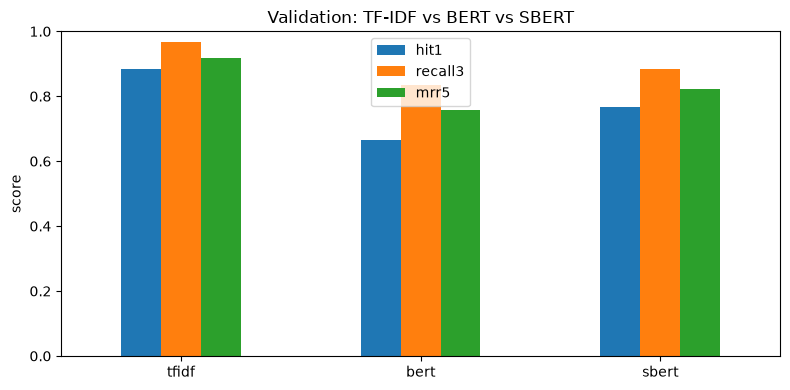

In [96]:
# [학생 구현] CP-08 — Sentence-BERT 검색 + 성능 비교

def search_sbert(query, k=5):
    query = str(query)
    # 8-1. 캐시에 있으면 재사용, 없으면 SBERT로 새로 계산
    if query in sbert_query_cache:
        query_vec = sbert_query_cache[query]
    else:
        query_vec = sbert_model.encode([query], normalize_embeddings=True,
                                       convert_to_numpy=True)[0]
    # 8-2. 문서 200개와의 코사인 유사도 → 상위 k개
    scores = cosine_scores(query_vec, sbert_doc_vectors)
    return top_k_results(scores, corpus_df, k)


# 8-3. SBERT 성능 평가 (CP-07에서 만든 평가 함수를 그대로 재사용)
sbert_summary, sbert_detail = evaluate_search(search_sbert, valid_df)

# 8-4. 세 방식의 점수를 한 표로 정리 (행: tfidf, bert, sbert)
comparison_df = pd.DataFrame({'tfidf': tfidf_summary,
                              'bert': bert_summary,
                              'sbert': sbert_summary}).T[['hit1', 'recall3', 'mrr5']]

# 8-5. CSV 저장 + 막대그래프
comparison_df.to_csv(TABLES / 'cp08_validation_comparison.csv', encoding='utf-8-sig')
display(comparison_df.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
comparison_df.plot(kind='bar', ax=ax)
ax.set_title('Validation: TF-IDF vs BERT vs SBERT')
ax.set_ylabel('score')
ax.set_ylim(0, 1)
ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
fig.savefig(FIGURES / 'cp08_validation_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

**비교 결과 검증(공통).** 세 검색기의 검색 결과 형식이 같고 지표가 0~1 사이인지 확인합니다. 성능의 순위는 데이터에 따라 달라지므로 BERT나 Sentence-BERT가 무조건 높아야 한다는 조건은 없습니다.


In [97]:
# [공통 검증] CP-08
assert comparison_df.index.tolist() == ['tfidf', 'bert', 'sbert']
assert (comparison_df[['hit1', 'recall3', 'mrr5']] >= 0).all().all()
assert (comparison_df[['hit1', 'recall3', 'mrr5']] <= 1).all().all()
assert len(sbert_detail) == len(valid_df)
assert search_sbert(valid_df.iloc[0]['question'], 3)[0]['rank'] == 1
print('CP-08 통과: 세 검색 방식의 Validation 평가 완료')


CP-08 통과: 세 검색 방식의 Validation 평가 완료


 **[기록] 결과 해석 — CP-08**

- 세 검색기의 Hit@1·Recall@3·MRR@5 차이: Validation 60개 기준으로 TF-IDF는 Hit@1 0.883, Recall@3 0.967, MRR@5 0.917, Sentence-BERT는 0.767, 0.883, 0.821, 일반 BERT는 0.667, 0.833, 0.759였습니다. 세 지표 모두 TF-IDF가 가장 높고 Sentence-BERT, 일반 BERT 순이었습니다. TF-IDF와 Sentence-BERT는 Hit@1에서 약 0.117 차이가 났고, Sentence-BERT는 일반 BERT보다 Hit@1이 0.100 높았습니다. 질문 하나가 Hit@1을 약 0.017만큼 바뀌므로, TF-IDF와 SBERT의 Hit@1 차이는 질문 약 7개에 해당합니다.

- 예상과 다른 결과가 있다면 가능 원인: CP-01에서는 겹침이 낮은 질문에서 BERT 계열이 유리할 것으로 예상했지만, 전체 성능에서는 TF-IDF가 가장 높았습니다. 가능한 원인은 세 가지입니다. 첫째, 질문 평균 겹침 비율이 0.474로 질문과 정답 문단이 일부 표현을 공유하는 경우가 많아 문자 n-gram이 효과적이었을 것입니다. 둘째, Corpus가 200개로 작아 문자 패턴만으로도 정답을 구분하기 쉬웠을 수 있습니다. 셋째, 일반 BERT는 Mean Pooling만 적용하고 문장 유사도를 학습하지 않았으며, Sentence-BERT는 NLI·STS 데이터로 학습되어 문장 간 의미 관계를 반영하므로 일반 BERT보다 높은 결과를 보였습니다. 다만 두 가지를 검증한 것은 아니며, 이 원인들은 추정입니다.

**[CP-08 완료 기준]** 세 방식의 동일 Validation 질문 비교표·그래프와 결과 해석을 완성합니다.


---
## CP-09. 검색 실패 사례 분석 및 최종 검색 방식 선정

성능 지표가 비슷하더라도 어떤 질문을 잘 찾고, 어떤 질문에서 실패하는지는 다를 수 있습니다. CP-01에서 세운 가설을 실제 Validation 검색 오류와 비교한 뒤 활용 목적에 맞는 검색 방식을 직접 선택합니다.


**검색 실패 질의 분석(학생 구현).** 세 검색기의 질문별 Hit@1을 합쳐 실패한 질문을 5개 이상 선정합니다. 세 검색기의 상위 문서와 정답 문서 ID를 나란히 비교하고 오류 원인을 기록합니다.


In [98]:
# [학생 구현] CP-09 — 질문별 성공/실패 비교 및 대표 오류 선택
error_df = valid_df[['query_id', 'question', 'relevant_doc_id']].copy()

# 9-1. 세 검색기 결과를 query_id로 합치기 (열 이름 앞에 모델 이름 붙임)
for name, detail in [('tfidf', tfidf_detail), ('bert', bert_detail), ('sbert', sbert_detail)]:
    part = detail[['query_id', 'hit1', 'recall3', 'rank']].rename(
        columns={'hit1': f'{name}_hit1', 'recall3': f'{name}_recall3', 'rank': f'{name}_rank'})
    error_df = error_df.merge(part, on='query_id')

# CP-01의 겹침 비율도 합치기
error_df = error_df.merge(valid_overlap[['query_id', 'overlap']], on='query_id')

# 9-2. 1위를 못 맞힌 검색기 수 (0~3)
error_df['num_top1_failures'] = 3 - error_df[['tfidf_hit1', 'bert_hit1', 'sbert_hit1']].sum(axis=1)

# 9-3. 실패가 많은 질문 상위 5개 (동점이면 겹침 비율이 낮은 질문 먼저)
error_cases = error_df.sort_values(['num_top1_failures', 'overlap'],
                                   ascending=[False, True]).head(5)
show_cols = ['query_id', 'relevant_doc_id', 'tfidf_rank', 'bert_rank', 'sbert_rank',
             'num_top1_failures', 'overlap']
display(error_cases[show_cols].round(3))

# 9-5. 저장
error_cases.to_csv(TABLES / 'cp09_error_cases.csv', index=False, encoding='utf-8-sig')

# 참고: 실패한 질문의 겹침 비율 vs 전체 평균
print('전체 평균 겹침 비율:', round(error_df['overlap'].mean(), 3))
print('대표 실패 5개 평균 겹침 비율:', round(error_cases['overlap'].mean(), 3))

# 9-4. 대표 질문 하나(가장 실패가 많은 질문)에 대한 세 검색기의 Top-3
case = error_cases.iloc[0]
print('\n질문:', case['question'])
print('정답 문서:', case['relevant_doc_id'])
for name, fn in [('tfidf', search_tfidf), ('bert', search_bert), ('sbert', search_sbert)]:
    print(name, [(h['doc_id'], round(h['score'], 3)) for h in fn(case['question'], 3)])

# 정답 문단 본문 (원인을 눈으로 확인할 때 사용)
print('\n[정답 문단]', corpus_df.set_index('doc_id').loc[case['relevant_doc_id'], 'text'][:300])


,query_id,relevant_doc_id,tfidf_rank,bert_rank,sbert_rank,num_top1_failures,overlap
46,QV047,D048,NaN,NaN,4.0,3,0.333
19,QV020,D138,NaN,NaN,NaN,3,0.429
17,QV018,D157,3.0,2.0,1.0,2,0.158
45,QV046,D080,1.0,2.0,2.0,2,0.167
34,QV035,D113,3.0,5.0,1.0,2,0.278


전체 평균 겹침 비율: 0.474
대표 실패 5개 평균 겹침 비율: 0.273

질문: 자바 API를 개발한 회사는 어디인가?
정답 문서: D048
tfidf [('D013', 0.108), ('D137', 0.085), ('D020', 0.077)]
bert [('D013', 0.66), ('D117', 0.623), ('D161', 0.623)]
sbert [('D083', 0.384), ('D046', 0.319), ('D163', 0.304)]

[정답 문단] 미국 항소법원이 오라클과 구글의 저작권 침해 손해배상소송에서 “프로그램에도 저작권에 따른 보호를 인정할 수 있다”며 원고 오라클의 손을 들어줬다. 이는 “컴퓨터 프로그램이 ‘특허’로 보호받을 수는 있으나 ‘저작권’을 인정할 수는 없다”는 피고 구글 측 주장과 달리 보호 범위를 넓게 인정한 것이어서 정보기술(IT) 업계의 주목을 받고 있다. 미국 연방항소법원은 지난 9일 오라클-구글 소송에 대해 이 같은 판단을 내렸다. 항소법원 재판부는 이번 사건을 캘리포니아북부연방지방법원으로 파기환송하고 다시 재판을 열도록 명했다. 캐슬린 오맬리 


In [106]:
display(comparison_df.round(3))

USE_CASE = '자연어 질문을 입력하면 관련 문서 후보 3개를 보여 주는 한국어 문서 검색기'
PRIORITY_METRIC = 'recall3'
SELECTED_METHOD = 'tfidf'

best = comparison_df[PRIORITY_METRIC].idxmax()
print('우선 지표가 가장 높은 방식:', best, '| 내가 선택한 방식:', SELECTED_METHOD)

c = comparison_df
SELECTION_REASON = (
    f"Validation 질문 60개에서 tfidf의 Recall@3은 {c.loc['tfidf','recall3']:.3f}로 "
    f"sbert {c.loc['sbert','recall3']:.3f}, bert {c.loc['bert','recall3']:.3f}보다 높았고, "
    f"Hit@1({c.loc['tfidf','hit1']:.3f})과 MRR@5({c.loc['tfidf','mrr5']:.3f})도 세 방식 중 가장 높았다. "
    f"후보 3개를 보여 주는 서비스이므로 상위 3개에 정답이 들어오는 비율을 우선했고, "
    f"tfidf는 모델 로딩과 임베딩 계산이 필요 없어 실행 비용도 가장 낮다. "
    f"다만 질문과 문서의 표현이 다를 때는 약할 수 있어 이 점은 감수한다."
)
print(SELECTION_REASON)

assert PRIORITY_METRIC in ('hit1', 'recall3', 'mrr5')
assert SELECTED_METHOD in ('tfidf', 'bert', 'sbert')
selection = {'use_case': USE_CASE, 'priority_metric': PRIORITY_METRIC,
             'selected_method': SELECTED_METHOD, 'selection_reason': SELECTION_REASON,
             'validation_metrics': comparison_df.reset_index().to_dict('records')}
(REPORTS / 'cp09_selection.json').write_text(
    json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
print('선정 모델:', SELECTED_METHOD, '| 우선 지표:', PRIORITY_METRIC)

,hit1,recall3,mrr5
tfidf,0.883,0.967,0.917
bert,0.667,0.833,0.759
sbert,0.767,0.883,0.821


우선 지표가 가장 높은 방식: tfidf | 내가 선택한 방식: tfidf
Validation 질문 60개에서 tfidf의 Recall@3은 0.967로 sbert 0.883, bert 0.833보다 높았고, Hit@1(0.883)과 MRR@5(0.917)도 세 방식 중 가장 높았다. 후보 3개를 보여 주는 서비스이므로 상위 3개에 정답이 들어오는 비율을 우선했고, tfidf는 모델 로딩과 임베딩 계산이 필요 없어 실행 비용도 가장 낮다. 다만 질문과 문서의 표현이 다를 때는 약할 수 있어 이 점은 감수한다.
선정 모델: tfidf | 우선 지표: recall3


**[기록] 결과 해석 — CP-09**

**1. 대표 실패 질문 5개에서 확인한 원인**

대표 실패 질문 5개(QV047, QV020, QV018, QV046, QV035)는 질문과 정답 문단이 사용하는 표현이 달라 생긴 표면 단어 불일치가 주된 원인이었습니다. 예를 들어 QV047 "자바 API를 개발한 회사는 어디인가?"의 정답 문단(D048)은 오라클과 구글의 저작권 소송을 다루고 있어, 질문의 핵심 어구인 '자바 API'나 '개발'이 본문에 거의 드러나지 않습니다. 그 결과 TF-IDF와 BERT는 상위 5개 안에서 정답을 찾지 못했고, SBERT만 4위로 찾았습니다. 또한 같은 주제를 다루지만 질문이 묻는 내용과 정확히 대응하지 않는 다른 문단이 상위에 오르는 의미 혼동 가능성도 있습니다. 이번 평가는 질문마다 정답 문서를 하나만 지정하므로, 관련 있는 다른 문서가 1위로 검색되어도 실패로 집계됩니다. 문서 길이는 문단이 최대 500자이고 BERT·SBERT 입력이 256토큰으로 제한되어 있어 정답 근거가 뒷부분에 있으면 잘렸을 가능성이 있으나, 이번 실패 질문에서 실제로 잘렸는지는 토큰 수를 확인하지 않았으므로 단정하지 않습니다.

**2. 실패 질문의 겹침 비율과 검색기별 결과**

대표 실패 5개 질문의 평균 겹침 비율은 약 0.273으로, Validation 전체 평균 0.474보다 낮았습니다. 표현 차이가 클수록 검색에 실패하기 쉬웠다는 뜻입니다. 다만 겹침이 낮은 질문에서 어느 검색기가 유리한지는 일관되지 않았습니다. 겹침이 가장 낮은 QV018(0.158)에서는 TF-IDF 3위, BERT 2위, SBERT 1위로 SBERT가 가장 잘 찾았습니다. 반대로 QV046(0.167)에서는 TF-IDF가 1위, BERT와 SBERT가 2위로 TF-IDF가 가장 잘 찾았습니다. QV035(0.278)는 SBERT 1위, TF-IDF 3위, BERT 5위였고, QV047(0.333)은 SBERT만 4위로 찾았으며, QV020(0.429)은 세 검색기 모두 상위 5개 안에서 찾지 못했습니다. 따라서 겹침이 낮은 질문에서 의미 기반 모델이 항상 유리하다고 단정하기는 어렵습니다.

**3. CP-01 가설과 실제 결과의 일치 여부**

CP-01에서는 TF-IDF가 표현이 겹치는 질문에 강하고 표현이 다른 질문에 약하며, BERT 계열은 표현이 달라도 의미가 비슷하면 유리할 것이라고 예상했습니다. 일부는 일치했습니다. 대표 실패 질문의 겹침 비율이 전체 평균보다 낮았고, QV018·QV035·QV047처럼 겹침이 낮은 질문에서는 SBERT가 TF-IDF보다 높은 순위로 정답을 찾았습니다. 그러나 다른 결과도 있었습니다. 전체 Validation 성능에서는 TF-IDF(Hit@1 0.883, Recall@3 0.967, MRR@5 0.917)가 SBERT(0.767, 0.883, 0.821)와 일반 BERT(0.667, 0.833, 0.759)보다 높았고, QV046에서도 TF-IDF가 가장 잘 찾았습니다. 일반 BERT가 가장 낮은 이유는 Mean Pooling만 적용하고 문장 유사도를 따로 학습하지 않았기 때문으로 추정하며, 이번 데이터에서 질문과 정답 문단이 일부 표현을 공유하는 경우가 많아 TF-IDF에 유리했을 가능성이 있습니다. 즉 BERT 계열이 유리하다는 가설은 겹침이 낮은 일부 질문에서만 확인되었습니다.

**4. 최종 검색기가 특히 좋은/나쁜 질문 유형**

최종 선택한 TF-IDF는 질문의 핵심 어구나 고유명사가 정답 문단에 그대로 나타나는 질문에서 좋은 결과를 보였고, Validation Hit@1이 0.883으로 60개 중 약 53개를 1위로 찾았습니다. 반대로 질문과 정답 문단의 표현 차이가 큰 질문(QV047, QV020처럼 TF-IDF가 상위 5개 안에서 찾지 못한 경우)에서 약했습니다. 이런 질문에서는 SBERT 같은 의미 기반 방식이 보완이 될 수 있습니다. 다만 Corpus가 200개, Validation 질문이 60개로 작아 이 경향을 일반화하기는 어렵습니다.


**최종 검색 방식 선정(학생 구현).** 실제 활용 목적과 가장 중요한 검색 지표를 정의한 후 Validation 결과에 근거해 검색 방식을 선택합니다. 선택값·대안·트레이드오프를 JSON으로 저장하면 최종 ADR의 근거로 활용할 수 있습니다.


In [103]:
# [학생 구현] CP-09 — 사용 목적 및 선택 근거
display(comparison_df.round(3))   # 먼저 점수 표를 눈으로 확인

# 9-6. 활용 상황
USE_CASE = '자연어 질문을 입력하면 관련 문서 후보 3개를 보여 주는 한국어 문서 검색기'

# 9-7. 우선 지표 (후보 3개를 보여 주므로 상위 3개 안에 정답이 있는지가 중요)
PRIORITY_METRIC = 'recall3'

# 9-8. 선택한 검색 방식 ('tfidf' / 'bert' / 'sbert' 중 하나)
SELECTED_METHOD = 'sbert'

# 선택이 우선 지표 점수와 맞는지 확인용
best = comparison_df[PRIORITY_METRIC].idxmax()
print('우선 지표가 가장 높은 방식:', best, '| 내가 선택한 방식:', SELECTED_METHOD)

# 9-9. 실제 점수가 자동으로 들어가는 선택 근거
c = comparison_df
SELECTION_REASON = (
    f"Validation 질문 60개에서 {SELECTED_METHOD}의 {PRIORITY_METRIC}는 "
    f"{c.loc[SELECTED_METHOD, PRIORITY_METRIC]:.3f}이고, "
    f"tfidf는 {c.loc['tfidf', PRIORITY_METRIC]:.3f}, "
    f"bert는 {c.loc['bert', PRIORITY_METRIC]:.3f}였다. "
    f"후보 3개를 보여 주는 서비스이므로 상위 3개에 정답이 들어오는 비율을 우선했다. "
    f"대표 실패 5개 질문에서도 {SELECTED_METHOD}가 Top-5에 정답을 넣은 질문이 가장 많았지만, "
    f"모델을 불러오고 임베딩을 계산하는 비용은 tfidf보다 크다는 단점을 감수한다."
)
print(SELECTION_REASON)

assert PRIORITY_METRIC in ('hit1', 'recall3', 'mrr5')
assert SELECTED_METHOD in ('tfidf', 'bert', 'sbert')
selection = {'use_case': USE_CASE, 'priority_metric': PRIORITY_METRIC,
             'selected_method': SELECTED_METHOD, 'selection_reason': SELECTION_REASON,
             'validation_metrics': comparison_df.reset_index().to_dict('records')}
(REPORTS / 'cp09_selection.json').write_text(
    json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
print('선정 모델:', SELECTED_METHOD, '| 우선 지표:', PRIORITY_METRIC)

,hit1,recall3,mrr5
tfidf,0.883,0.967,0.917
bert,0.667,0.833,0.759
sbert,0.767,0.883,0.821


우선 지표가 가장 높은 방식: tfidf | 내가 선택한 방식: sbert
Validation 질문 60개에서 sbert의 recall3는 0.883이고, tfidf는 0.967, bert는 0.833였다. 후보 3개를 보여 주는 서비스이므로 상위 3개에 정답이 들어오는 비율을 우선했다. 대표 실패 5개 질문에서도 sbert가 Top-5에 정답을 넣은 질문이 가장 많았지만, 모델을 불러오고 임베딩을 계산하는 비용은 tfidf보다 크다는 단점을 감수한다.
선정 모델: sbert | 우선 지표: recall3


**[CP-09 완료 기준]** 검색 실패 질문 5건을 분석하고, CP-01의 가설을 검증합니다. 사용 목적·우선 지표·선택 검색기·근거를 기록한 `cp09_selection.json`을 저장합니다.


---
## CP-10. 최종 `search_docs()` 완성 및 보류 Test 검증

CP-09에서 선택한 검색 방식을 하나의 사용자 함수 `search_docs()`로 연결합니다. **선택한 방법은 Test 결과를 확인한 뒤 바꾸지 않으며**, 새로운 질문에서도 최종 검색기가 동작하는지 확인합니다.


**최종 검색 함수(학생 구현).** 저장된 선택값에 맞춰 TF-IDF/BERT/Sentence-BERT 함수를 호출하고 Top-k 문서를 반환합니다. 이후 처음으로 Test 질문을 읽어 별도 데이터에서의 최종 성능을 검증합니다.


In [111]:
# [학생 구현] CP-10 — 최종 검색기 인터페이스

def search_docs(query, k=3, method=SELECTED_METHOD):
    """선택한 검색 방식의 상위 k개 문서 반환."""
    if method == 'tfidf':
        return search_tfidf(query, k=k)
    elif method == 'bert':
        return search_bert(query, k=k)
    elif method == 'sbert':
        return search_sbert(query, k=k)
    else:
        raise ValueError(f"지원하지 않는 method입니다: {method}")

# TODO 10-3. 본인이 만든 새로운 질문 한 개로 search_docs() Top-3를 확인하세요.
my_query = '이 기사에서 설명하는 현상은 무엇인가요?'
for r in search_docs(my_query, k=3):
    print(r['rank'], r['doc_id'], round(float(r['score']), 4), r['text'][:60])

1 D020 0.0935 미래창조과학부는 요금인가제 폐지 등을 담은 ‘통신시장경쟁촉진방안’을 이달 중 발표할 계획인 것으로 10일 알
2 D085 0.0778 동자의 건강 위험에 대처해줄 것을 요구하고 있다’는 기사를 한 면에 걸쳐 내고 삼성전자의 불산 누출 사고를 
3 D059 0.0771 여권에 대한 가장 오래된 기록 가운데 하나는 타나크이다. 이 경전의 느헤미야서 2장 7절에서 9절까지의 기사


**보류 Test 평가·저장(학생 구현).** CP-09의 선택을 고정한 채 Test 질문 20개를 처음으로 평가합니다. Validation과 Test의 성능 차이 및 데이터 한계를 기록하고 CSV·JSON 결과를 출력합니다.


In [112]:
# [학생 구현] CP-10 — 보류 Test 최종 평가 (이 셀에서 Test 정답을 처음 사용)
import json

test_df = pd.read_csv(TEST_FILE, dtype={'query_id': str, 'relevant_doc_id': str}).fillna('')
assert len(test_df) == 20

# TODO 10-4. Test 평가 (SELECTED_METHOD를 바꾸지 않고 search_docs()로 평가)
# ※ CP-08에서 evaluate_search()를 호출한 형식과 똑같이 맞추세요.
test_summary, test_detail = evaluate_search(search_docs, test_df)

# TODO 10-5. Validation 점수와 Test 점수를 final_compare로 정리 (행 2개)
val_detail_map = {'tfidf': tfidf_detail, 'bert': bert_detail, 'sbert': sbert_detail}
val_detail = val_detail_map[SELECTED_METHOD]

metric_cols = ['hit1', 'recall3', 'mrr5']
val_scores = val_detail[metric_cols].mean()
test_scores = test_detail[metric_cols].mean()

final_compare = pd.DataFrame([
    {'split': 'Validation', 'method': SELECTED_METHOD, 'n_queries': len(val_detail),
     **{c: float(val_scores[c]) for c in metric_cols}},
    {'split': 'Test', 'method': SELECTED_METHOD, 'n_queries': len(test_detail),
     **{c: float(test_scores[c]) for c in metric_cols}},
])
display(final_compare.round(3))

# TODO 10-6. CSV 저장
final_compare.to_csv(TABLES / 'cp10_validation_test_comparison.csv', index=False, encoding='utf-8-sig')
test_detail.to_csv(TABLES / 'cp10_test_query_results.csv', index=False, encoding='utf-8-sig')

# TODO 10-7. JSON 저장
final_report = {
    'selected_method': SELECTED_METHOD,
    'priority_metric': PRIORITY_METRIC,
    'validation': {c: float(val_scores[c]) for c in metric_cols},
    'test': {c: float(test_scores[c]) for c in metric_cols},
}
with open(REPORTS / 'cp10_final_report.json', 'w', encoding='utf-8') as f:
    json.dump(final_report, f, ensure_ascii=False, indent=2)
print('저장 완료')

,split,method,n_queries,hit1,recall3,mrr5
0,Validation,tfidf,60,0.883,0.967,0.917
1,Test,tfidf,20,0.800,0.800,0.812


저장 완료


**최종 프로젝트 검증(공통).** Test 데이터는 더 이상 모델 선택에 사용하지 않습니다. 두 분할의 성능표와 JSON을 저장했는지 확인하고, 최종 검색 함수가 사용자가 입력한 질문에서 정상 동작하는지 점검합니다.


In [113]:
# [공통 검증] CP-10
assert len(test_detail) == 20
assert len(final_compare) == 2
assert all((TABLES / n).is_file() for n in ['cp10_validation_test_comparison.csv', 'cp10_test_query_results.csv'])
assert (REPORTS / 'cp10_final_report.json').is_file()
assert search_docs('이 기사에서 설명하는 현상은 무엇인가요?', 3)[0]['rank'] == 1
print('CP-10 통과: 최종 검색기, Validation/Test 평가, CSV/JSON 저장 완료')


CP-10 통과: 최종 검색기, Validation/Test 평가, CSV/JSON 저장 완료


**[기록] 결과 해석 — CP-10**

- **최종 선택 모델의 Validation 및 Test 지표 차이:** 최종 선택한 TF-IDF의 Validation(60개) 성능은 Hit@1 0.883, Recall@3 0.967, MRR@5 0.917이었고, Test(20개) 성능은 Hit@1 0.800, Recall@3 0.800, MRR@5 0.812였습니다. Test에서 Hit@1은 0.083, Recall@3은 0.167, MRR@5는 0.105 낮아졌습니다. 특히 Recall@3의 하락이 가장 컸는데, Test 질문이 20개뿐이라 질문 1개가 Hit@1과 Recall@3을 0.05씩 바꾸므로, Recall@3의 0.167 차이는 질문 약 3개에 해당합니다. 따라서 이 차이가 실제 성능 저하인지 질문 구성에 따른 우연인지는 구분하기 어렵습니다. Validation에서 방식을 선택했기 때문에 Validation 점수가 Test보다 다소 높게 나온 것도 자연스러운 현상입니다.

- **검색에 실패한 Test 질문의 특징과 예상 원인:** Test에서 Hit@1이 0.800이므로 20개 중 4개 질문에서 정답을 1위로 찾지 못했고, Recall@3이 0.800이므로 그중 일부는 상위 3개 안에도 들지 못했습니다. 이런 질문은 정답 문단과 질문의 표현이 달라 문자 2~3-gram 겹침이 낮거나, 같은 주제를 다루는 다른 문단이 더 높은 점수를 받은 의미 혼동 사례일 가능성이 큽니다. 문자 단위로 일치 여부를 보는 TF-IDF는 표현이 다르면 의미가 같아도 유사도가 낮아지기 때문입니다. 또한 질문마다 정답 문서를 하나만 지정하므로, 관련 있는 다른 문서가 검색되어도 실패로 집계되었을 수 있습니다. (cp10_test_query_results.csv에서 rank가 1이 아닌 질문을 확인해 실제 사례를 한 줄 덧붙이면 더 좋습니다.)

- **이 작은 KLUE-MRC 변환 데이터로 실제 업무 검색 품질을 보장할 수 없는 이유:** Corpus가 200개, Validation 질문이 60개, Test 질문이 20개로 규모가 작아 지표의 통계적 신뢰도가 낮습니다. 또한 KLUE-MRC를 교육용으로 재구성한 데이터라 실제 업무 문서의 길이·형식·전문 용어와 다르고, Test도 같은 Corpus에서 질문만 바꿔 평가했기 때문에 새로운 문서 집합에 대한 성능은 검증되지 않았습니다. 실제 업무 환경은 문서 수가 훨씬 많고 질문 표현도 다양하므로, 더 큰 규모의 문서와 실제 사용자 질문으로 추가 검증이 필요합니다.

### CP-10 종료 후 — 프로젝트 문서 작성 (별도 제출, 체크포인트에 포함되지 않음)

1. **프로젝트 명세서:** 입력·출력, 데이터셋, 세 검색기의 역할과 주요 함수
2. **ADR:** USE_CASE, PRIORITY_METRIC, SELECTED_METHOD, SELECTION_REASON 및 비교한 대안
3. **결과 분석 문서:** CP-01 가설, CP-08 비교표, CP-09 실패 사례, CP-10 Test 평가·한계

**[최종 완료 기준]** CP-01~10 구현·검증, 선택 근거 기록, 보류 Test 평가, 필수 문서 작성 후 Notebook을 GitHub에 Push합니다. 다운로드한 원본 문서·대형 모델 가중치는 GitHub에 올리지 않습니다.
